# Descarga de datos: imágenes NISAR de lluvias en ciudades del Perú (solo la ciudad)

Descarga imágenes de radar **NISAR** (NASA-ISRO, banda L) en su producto **RSLC** de nivel 1, tal como las entrega el
satélite (sin preprocesar), tomadas el día de una lluvia o en las horas siguientes, mientras el agua puede seguir empozada,
y días secos de la misma pista como referencia. La geocodificación y todo lo demás lo hace el notebook 01.

* **Fuente:** archivo de la NASA en ASF. Hace falta una cuenta gratuita de NASA Earthdata guardada en `~/.netrc`
  (`machine urs.earthdata.nasa.gov login <usuario> password <clave>`), que `requests` usa sola.
* **Formato:** HDF5 (`.h5`): números complejos en geometría de radar, la grilla de geolocalización y los metadatos.
* **Solo la ciudad:** cada archivo (cuadro) trae una franja de 120-260 km × 250 km (30 000-63 000 km², 4-28 GB) y la
  ciudad ocupa una parte pequeña. El archivo se lee en el servidor y se bajan solo los bloques que cubren la ciudad.
* **Destino:** `Data/crudos_nisar/<ciudad>/`.
* **Ciudades:** Lima Metropolitana y Callao (lloviznas y aniegos de 2026), Tumbes (lluvia del 23 oct 2026) y Arequipa
  (lluvia del 16 feb 2026).

## 1. Lluvias y pasadas

NISAR pasa por cada lugar cada 12 días por cada pista. Se eligieron las pasadas de cada ciudad que caen el mismo día o al día
siguiente de una lluvia confirmada por la prensa, y días secos de la misma pista (misma hora y ángulo de vista). Una pasada
puede necesitar dos cuadros seguidos para cubrir toda la ciudad (en Lima: 094 y 095 en la pista 083; 171 y 172 en la 003).

| Descartado | Motivo |
|---|---|
| Piura (19-20 y 27-28 oct 2026) | las pasadas fueron el 19 oct a las 06:09 y 18:40 (antes de la lluvia) y el 31 oct, 3 días después |
| Juliaca (17 feb 2026) | el Senamhi reporta febrero 2026 deficiente de lluvia en Puno |
| Arequipa, desbordes del 19 y 22 feb | la pasada siguiente fue el 1 mar, 7-10 días después |
| Tumbes, temporal del 1-3 nov | la pasada del 5 nov aún no se publica |
| ciudades fuera del Perú | solo ciudades del Perú |

In [1]:
import io, warnings
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path
import numpy as np, pandas as pd, requests, h5py, matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=DeprecationWarning)

cajas = {"lima": (-77.18, -12.30, -76.75, -11.80), "tumbes": (-80.50, -3.62, -80.22, -3.45),
         "arequipa": (-71.66, -16.47, -71.46, -16.28)}
alturas_ciudad = {"lima": (0, 2000), "tumbes": (0, 150), "arequipa": (2000, 3700)}
escenas = pd.DataFrame([
    ("lima", "083_D", "2025-11-03", "seco", ""), ("lima", "083_D", "2025-11-27", "seco", ""),
    ("lima", "083_D", "2026-01-14", "lluvia", "lluvias del 9 al 16 ene 2026 (emergencia en Lima)"),
    ("lima", "083_D", "2026-07-01", "seco", ""), ("lima", "083_D", "2026-07-13", "seco", ""),
    ("lima", "083_D", "2026-07-25", "seco", ""),
    ("lima", "083_D", "2026-08-18", "lluvia", "lluvia del 16-17 ago en VMT y VES (bus varado en el baipás Nueva Esperanza)"),
    ("lima", "083_D", "2026-08-30", "seco", ""),
    ("lima", "083_D", "2026-10-05", "lluvia", "baipás Nueva Esperanza inundado la madrugada del 2 oct"),
    ("lima", "083_D", "2026-10-17", "seco", ""),
    ("lima", "003_A", "2025-10-29", "seco", ""), ("lima", "003_A", "2026-08-25", "seco", ""),
    ("lima", "003_A", "2026-09-06", "seco", ""), ("lima", "003_A", "2026-09-30", "seco", ""),
    ("lima", "003_A", "2026-10-12", "seco", ""),
    ("lima", "003_A", "2026-10-24", "lluvia", "llovizna intensa del 22 oct"),
    ("lima", "003_A", "2026-11-05", "lluvia", "aniegos del 4-5 nov en Lima Sur"),
    ("tumbes", "003_A", "2026-07-20", "seco", ""), ("tumbes", "003_A", "2026-08-13", "seco", ""),
    ("tumbes", "003_A", "2026-10-24", "lluvia", "8 h de lluvia la madrugada del 23 oct: Puerto Pizarro, Zarumilla, barrio San José"),
    ("arequipa", "046_A", "2026-02-17", "lluvia", "lluvia del 16 feb desde las 16:00: baipás Venezuela, Av. Goyeneche, Yura"),
    ("arequipa", "046_A", "2026-06-29", "seco", ""), ("arequipa", "046_A", "2026-07-11", "seco", ""),
], columns=["ciudad", "pista", "fecha", "dia", "lluvia"])


def buscar(e):
    o, s, este, n = cajas[e.ciudad]
    q = {"platform": "NISAR", "intersectsWith": f"POLYGON(({o} {s},{este} {s},{este} {n},{o} {n},{o} {s}))",
         "start": f"{e.fecha}T00:00:00Z", "end": f"{e.fecha}T23:59:59Z", "output": "geojson"}
    hallados = requests.get("https://api.daac.asf.alaska.edu/services/search/param", params=q, timeout=300).json()["features"]
    urls = [h["properties"]["url"] for h in hallados if "_RSLC_" in h["properties"]["fileID"] and f"_{e.pista}_" in h["properties"]["fileID"]]
    return sorted({u.split("/")[-1][27:30]: u for u in sorted(urls, key=lambda u: u.split("_")[-5][1:])}.values())


with ThreadPoolExecutor(6) as ex:
    escenas["urls"] = list(ex.map(buscar, escenas.itertuples()))
escenas["cuadros"] = escenas.urls.apply(lambda u: "+".join(x.split("/")[-1][27:30] for x in u))
escenas["hora_utc"] = pd.to_datetime(escenas.urls.str[0].str.extract(r"_(\d{8}T\d{6})_")[0])
escenas["hora_local"] = escenas.hora_utc - pd.Timedelta(hours=5)
print((escenas.urls.str.len() == 0).sum(), "pasadas aún no publicadas")
escenas[["ciudad", "pista", "cuadros", "hora_local", "dia", "lluvia"]]

1 pasadas aún no publicadas


,ciudad,pista,cuadros,hora_local,dia,lluvia
0,lima,083_D,095,2025-11-03 18:25:53,seco,
1,lima,083_D,095,2025-11-27 18:25:54,seco,
2,lima,083_D,095,2026-01-14 18:25:56,lluvia,lluvias del 9 al 16 ene 2026 (emergencia en Lima)
3,lima,083_D,094+095,2026-07-01 18:25:21,seco,
4,lima,083_D,094+095,2026-07-13 18:25:21,seco,
5,lima,083_D,094+095,2026-07-25 18:25:20,seco,
6,lima,083_D,094+095,2026-08-18 18:25:19,lluvia,lluvia del 16-17 ago en VMT y VES (bus varado ...
7,lima,083_D,094+095,2026-08-30 18:25:19,seco,
8,lima,083_D,094+095,2026-10-05 18:25:19,lluvia,baipás Nueva Esperanza inundado la madrugada d...
9,lima,083_D,094+095,2026-10-17 18:25:19,seco,


### 1.1 ¿Cuánto llovió antes de cada pasada?

Precipitación horaria del modelo meteorológico de Open-Meteo en cada ciudad (es un modelo, no una estación) en las 12 h,
3 días y 7 días antes de cada pasada. En Tumbes y Arequipa separa bien las lluvias de los días secos. En Lima la garúa moja
casi todas las semanas y el modelo da pocos milímetros tanto antes de las lluvias como antes de los días "secos": ahí las
lluvias se eligieron por las noticias de aniegos, no por la cantidad de lluvia.

In [2]:
puntos = {"lima": (-12.1804, -76.9435), "tumbes": (-3.567, -80.451), "arequipa": (-16.399, -71.537)}


def lluvia_horaria(ciudad):
    lat, lon = puntos[ciudad]
    r = requests.get("https://historical-forecast-api.open-meteo.com/v1/forecast", timeout=120,
                     params={"latitude": lat, "longitude": lon, "start_date": "2025-10-01",
                             "end_date": pd.Timestamp.now().strftime("%Y-%m-%d"), "hourly": "precipitation", "timezone": "GMT"}).json()
    return pd.Series(r["hourly"]["precipitation"], index=pd.to_datetime(r["hourly"]["time"])).fillna(0)


horaria = {c: lluvia_horaria(c) for c in puntos}
for horas in (12, 72, 168):
    escenas[f"mm_{horas}h_antes"] = [horaria[e.ciudad][e.hora_utc.floor("h") - pd.Timedelta(hours=horas):e.hora_utc.floor("h")].sum()
                                     if pd.notna(e.hora_utc) else np.nan for e in escenas.itertuples()]
escenas[["ciudad", "pista", "fecha", "dia", "mm_12h_antes", "mm_72h_antes", "mm_168h_antes"]].round(1)

,ciudad,pista,fecha,dia,mm_12h_antes,mm_72h_antes,mm_168h_antes
0,lima,083_D,2025-11-03,seco,0.0,0.1,0.4
1,lima,083_D,2025-11-27,seco,0.2,0.2,0.3
2,lima,083_D,2026-01-14,lluvia,0.0,0.9,8.8
3,lima,083_D,2026-07-01,seco,0.3,1.2,3.9
4,lima,083_D,2026-07-13,seco,0.0,0.4,1.3
5,lima,083_D,2026-07-25,seco,0.0,0.9,3.5
6,lima,083_D,2026-08-18,lluvia,0.1,3.8,9.1
7,lima,083_D,2026-08-30,seco,0.0,0.8,2.1
8,lima,083_D,2026-10-05,lluvia,0.0,0.4,5.6
9,lima,083_D,2026-10-17,seco,1.2,2.5,7.2


## 2. Descarga: solo la ciudad

`h5py` puede abrir un archivo a través de cualquier objeto que sepa leer y moverse (`read`, `seek`). `Remoto` es ese objeto:
cada vez que h5py pide unos bytes, los pide al servidor con la cabecera HTTP `Range`, así que solo viaja lo que se lee.

1. Se leen los tiempos de azimut, las distancias y la grilla de geolocalización del archivo.
2. Con la grilla, a la altura mínima y máxima de la ciudad, se ubican las filas y columnas que cubren su caja (con un margen
   de ~3 km), redondeadas a los bloques de 512 × 512 en que está guardado HH.
3. Se guarda un `.h5` con la misma estructura interna que el original: HH recortado (números complejos sin tocar), tiempos y
   distancias recortados, la grilla de geolocalización completa y la identificación del producto. En los atributos quedan la
   URL de origen y la posición del recorte.

Lo que ya existe no se vuelve a bajar.

In [3]:
class Remoto(io.RawIOBase):
    def __init__(self, url):
        self.sesion, self.pos, self.bajado = requests.Session(), 0, 0
        r = self.sesion.get(url, headers={"Range": "bytes=0-0"}, timeout=120)
        r.raise_for_status()
        self.url, self.n = r.url, int(r.headers["Content-Range"].split("/")[1])

    def readable(self):
        return True

    def seekable(self):
        return True

    def seek(self, pos, desde=0):
        self.pos = [pos, self.pos + pos, self.n + pos][desde]
        return self.pos

    def tell(self):
        return self.pos

    def readinto(self, b):
        fin = min(self.pos + len(b), self.n)
        if fin <= self.pos:
            return 0
        r = self.sesion.get(self.url, headers={"Range": f"bytes={self.pos}-{fin - 1}"}, timeout=120)
        r.raise_for_status()
        b[:len(r.content)] = r.content
        self.pos += len(r.content)
        self.bajado += len(r.content)
        return len(r.content)


def recortar(e):
    destino = Path(f"Data/crudos_nisar/{e.ciudad}") / e.url.split("/")[-1]
    if destino.exists():
        return
    destino.parent.mkdir(parents=True, exist_ok=True)
    o, s, este, n = cajas[e.ciudad]
    remoto = Remoto(e.url)
    with h5py.File(io.BufferedReader(remoto, 1 << 22)) as f:
        g, sw = f["science/LSAR/RSLC/metadata/geolocationGrid"], f["science/LSAR/RSLC/swaths"]
        t, r = sw["zeroDopplerTime"][()], sw["frequencyA/slantRange"][()]
        alturas, gt, gr = g["heightAboveEllipsoid"][()], g["zeroDopplerTime"][()], g["slantRange"][()]
        filas, cols = [], []
        for h in alturas_ciudad[e.ciudad]:
            k = np.argmin(abs(alturas - h))
            X, Y = g["coordinateX"][k], g["coordinateY"][k]
            i, j = np.nonzero((X > o - 0.03) & (X < este + 0.03) & (Y > s - 0.03) & (Y < n + 0.03))
            filas += [x for x in (gt[i] - t[0]) / (t[1] - t[0]) if 0 <= x < len(t)]
            cols += [x for x in (gr[j] - r[0]) / (r[1] - r[0]) if 0 <= x < len(r)]
        if not filas or not cols:
            return
        a0, a1 = int(min(filas)) // 512 * 512, min(len(t), (int(max(filas)) // 512 + 1) * 512)
        r0, r1 = int(min(cols)) // 512 * 512, min(len(r), (int(max(cols)) // 512 + 1) * 512)
        with h5py.File(destino.with_suffix(".tmp"), "w") as d:
            d["science/LSAR/RSLC/swaths/zeroDopplerTime"] = t[a0:a1]
            d["science/LSAR/RSLC/swaths/frequencyA/slantRange"] = r[r0:r1]
            d["science/LSAR/RSLC/swaths/frequencyA/listOfPolarizations"] = np.array([b"HH"])
            d.create_dataset("science/LSAR/RSLC/swaths/frequencyA/HH", data=sw["frequencyA/HH"][a0:a1, r0:r1], chunks=(512, 512),
                             compression="gzip")
            for k in ["coordinateX", "coordinateY", "zeroDopplerTime", "slantRange", "heightAboveEllipsoid"]:
                d.create_dataset(f"science/LSAR/RSLC/metadata/geolocationGrid/{k}", data=g[k][()], compression="gzip")
            f.copy(f["science/LSAR/identification"], d["science/LSAR"])
            d.attrs.update({"origen": e.url, "recorte_filas": [a0, a1], "recorte_columnas": [r0, r1]})
    destino.with_suffix(".tmp").rename(destino)
    print(f"{e.ciudad} {e.fecha} cuadro {destino.name[27:30]}: bajados {remoto.bajado / 1e9:.2f} GB de un archivo de {remoto.n / 1e9:.1f} GB")


archivos = escenas.explode("urls").dropna(subset=["urls"]).rename(columns={"urls": "url"})
with ThreadPoolExecutor(6) as ex:
    list(ex.map(recortar, archivos.itertuples()))

In [4]:
filas = []
for h5 in sorted(Path("Data/crudos_nisar").glob("*/*.h5")):
    with h5py.File(h5) as f:
        hh = f["science/LSAR/RSLC/swaths/frequencyA/HH"]
        filas.append({"ciudad": h5.parent.name, "archivo": h5.name[:58], "filas x columnas": f"{hh.shape[0]} x {hh.shape[1]}",
                      "GB": h5.stat().st_size / 1e9})
inventario = pd.DataFrame(filas)
print(f"{len(inventario)} archivos · {inventario.GB.sum():.1f} GB")
inventario.round(2)

37 archivos · 12.8 GB


,ciudad,archivo,filas x columnas,GB
0,arequipa,NISAR_L1_PR_RSLC_013_046_A_169_2005_DHDH_A_202...,7632 x 4608,0.22
1,arequipa,NISAR_L1_PR_RSLC_013_046_A_170_2005_DHDH_A_202...,3072 x 4096,0.12
2,arequipa,NISAR_L1_PR_RSLC_024_046_A_169_2005_DHDH_A_202...,7680 x 4608,0.23
3,arequipa,NISAR_L1_PR_RSLC_024_046_A_170_2005_DHDH_A_202...,2048 x 4096,0.10
4,arequipa,NISAR_L1_PR_RSLC_025_046_A_169_2005_DHDH_A_202...,7680 x 4608,0.23
5,arequipa,NISAR_L1_PR_RSLC_025_046_A_170_2005_DHDH_A_202...,1536 x 4096,0.09
6,lima,NISAR_L1_PR_RSLC_004_003_A_171_2005_DHDH_A_202...,12496 x 6656,0.44
7,lima,NISAR_L1_PR_RSLC_004_083_D_095_2005_SHSH_A_202...,7168 x 7168,0.28
8,lima,NISAR_L1_PR_RSLC_006_083_D_095_2005_SHSH_A_202...,6656 x 7168,0.26
9,lima,NISAR_L1_PR_RSLC_010_083_D_095_2005_SHSH_A_202...,7680 x 7680,0.32


## 3. Cómo se ve una imagen original

Una RSLC guarda números complejos en **geometría de radar**: filas = tiempo de vuelo (azimut, 4.5 m), columnas = distancia al
satélite (rango, 3-7 m). Se muestra la amplitud de un recorte de lluvia de cada ciudad, sin geocodificar (por eso aparece
girada o en espejo respecto del mapa y estirada en una dirección).

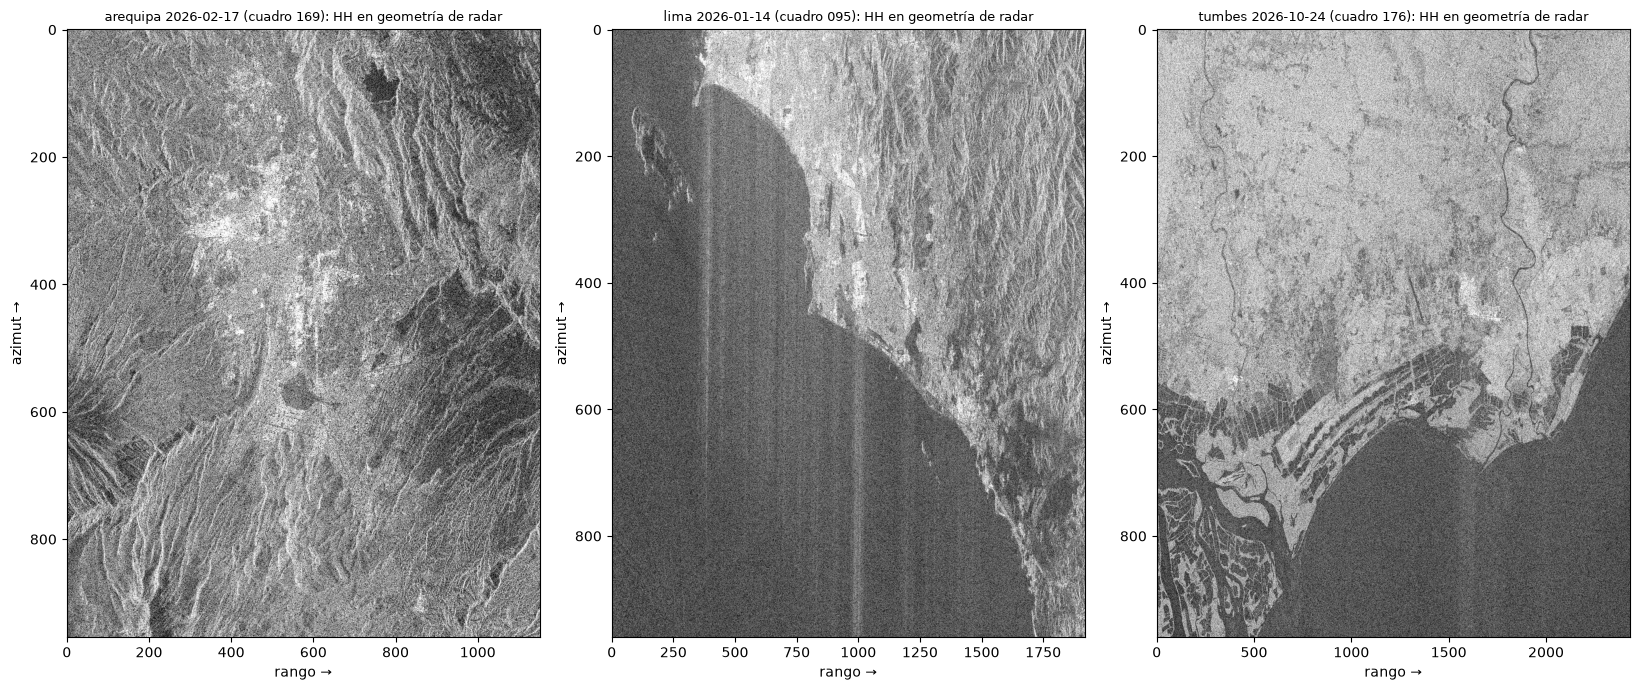

In [5]:
lluvias = archivos[archivos.dia == "lluvia"].groupby("ciudad").first()
fig, ejes = plt.subplots(1, len(lluvias), figsize=(5.5 * len(lluvias), 7), squeeze=False)
for ax, (ciudad, e) in zip(ejes[0], lluvias.iterrows()):
    with h5py.File(Path(f"Data/crudos_nisar/{ciudad}") / e.url.split("/")[-1]) as f:
        hh = f["science/LSAR/RSLC/swaths/frequencyA/HH"][::8, ::4]
    db = 10 * np.log10(np.abs(hh) ** 2 + 1e-10)
    ax.imshow(db, cmap="gray", vmin=np.percentile(db[db > -90], 2), vmax=np.percentile(db[db > -90], 98), aspect="auto")
    ax.set_title(f"{ciudad} {e.fecha} (cuadro {e.url.split('/')[-1][27:30]}): HH en geometría de radar", fontsize=9)
    ax.set_xlabel("rango →")
    ax.set_ylabel("azimut →")
plt.tight_layout()